In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

Cell 2 — Paths

In [2]:
PROCESSED_DIR = Path("../dataset/processed")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

Cell 3 — Load processed data

In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy")
X_val = np.load(PROCESSED_DIR / "X_val.npy")
X_test = np.load(PROCESSED_DIR / "X_test.npy")

y_train = np.load(PROCESSED_DIR / "y_train.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (6183, 17)
X_val: (1325, 17)
X_test: (1326, 17)
y_train: (6183,)
y_val: (1325,)
y_test: (1326,)


Cell 4 — Reshape data for LSTM

In [6]:
X_train_lstm = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_val_lstm = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train_lstm:", X_train_lstm.shape)
print("X_val_lstm:", X_val_lstm.shape)
print("X_test_lstm:", X_test_lstm.shape)

X_train_lstm: (6183, 1, 17)
X_val_lstm: (1325, 1, 17)
X_test_lstm: (1326, 1, 17)


Cell 4 — Class weights

In [7]:
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights_values))

print("Class weights:")
print(class_weights)

Class weights:
{0: np.float64(5.973913043478261), 1: np.float64(0.6813223140495868), 2: np.float64(0.7326697476004266)}


Cell 6 — Build LSTM model

In [8]:
num_classes = len(np.unique(y_train))

lstm_model = Sequential([
    LSTM(
        64,
        input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]),
        return_sequences=False
    ),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

lstm_model.summary()

c:\Users\DELL\Documents\projet_pfa\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,843 (108.76 KB)

 Trainable params: 27,587 (107.76 KB)

 Non-trainable params: 256 (1.00 KB)

Cell 7 — Compile model

In [9]:
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Cell 8 — Callbacks

In [10]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        MODELS_DIR / "lstm_model.h5",
        monitor="val_accuracy",
        save_best_only=True
    )
]

Cell 9 — Train LSTM

In [11]:
history = lstm_model.fit(
    X_train_lstm,
    y_train,
    validation_data=(X_val_lstm, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
180/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4882 - loss: 1.0099

194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5950 - loss: 0.7976 - val_accuracy: 0.8528 - val_loss: 0.6294 - learning_rate: 0.0010
Epoch 2/100
165/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7186 - loss: 0.5721

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7333 - loss: 0.5281 - val_accuracy: 0.8755 - val_loss: 0.3940 - learning_rate: 0.0010
Epoch 3/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7690 - loss: 0.4851 - val_accuracy: 0.8385 - val_loss: 0.3779 - learning_rate: 0.0010
Epoch 4/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7909 - loss: 0.4444 - val_accuracy: 0.8294 - val_loss: 0.3764 - learning_rate: 0.0010
Epoch 5/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8051 - loss: 0.3943 - val_accuracy: 0.8589 - val_loss: 0.3285 - learning_rate: 0.0010
Epoch 6/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8085 - loss: 0.3944 - val_accuracy: 0.8747 - val_loss: 0.2851 - learning_rate: 0.0010
Epoch 7/100
179/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8217 - loss: 0.3913

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8248 - loss: 0.3655 - val_accuracy: 0.8868 - val_loss: 0.2636 - learning_rate: 0.0010
Epoch 8/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8333 - loss: 0.3461 - val_accuracy: 0.8709 - val_loss: 0.2982 - learning_rate: 0.0010
Epoch 9/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8386 - loss: 0.3459 - val_accuracy: 0.8649 - val_loss: 0.3056 - learning_rate: 0.0010
Epoch 10/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8360 - loss: 0.3417 - val_accuracy: 0.8755 - val_loss: 0.2663 - learning_rate: 0.0010
Epoch 11/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8415 - loss: 0.3262 - val_accuracy: 0.8823 - val_loss: 0.2637 - learning_rate: 0.0010
Epoch 12/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8379 - loss: 0.3235 - val_accuracy: 0.8808 - val_loss: 0.2452 - learning_rate: 0.0010
Epoch 13/100
175/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8282 - loss: 0.3352

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8386 - loss: 0.3270 - val_accuracy: 0.8913 - val_loss: 0.2488 - learning_rate: 0.0010
Epoch 14/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8499 - loss: 0.3132 - val_accuracy: 0.8898 - val_loss: 0.2518 - learning_rate: 0.0010
Epoch 15/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8559 - loss: 0.3045 - val_accuracy: 0.8906 - val_loss: 0.2428 - learning_rate: 0.0010
Epoch 16/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8496 - loss: 0.3097 - val_accuracy: 0.8740 - val_loss: 0.2710 - learning_rate: 0.0010
Epoch 17/100
175/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8480 - loss: 0.2948

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8478 - loss: 0.3066 - val_accuracy: 0.8989 - val_loss: 0.2293 - learning_rate: 0.0010
Epoch 18/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8428 - loss: 0.3218 - val_accuracy: 0.8823 - val_loss: 0.2382 - learning_rate: 0.0010
Epoch 19/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8455 - loss: 0.3067 - val_accuracy: 0.8823 - val_loss: 0.2558 - learning_rate: 0.0010
Epoch 20/100
184/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8702 - loss: 0.2946

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8656 - loss: 0.2913 - val_accuracy: 0.9072 - val_loss: 0.2334 - learning_rate: 0.0010
Epoch 21/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8567 - loss: 0.3134 - val_accuracy: 0.8823 - val_loss: 0.2625 - learning_rate: 0.0010
Epoch 22/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8574 - loss: 0.3020 - val_accuracy: 0.8830 - val_loss: 0.2671 - learning_rate: 0.0010
Epoch 23/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8599 - loss: 0.2986 - val_accuracy: 0.8891 - val_loss: 0.2481 - learning_rate: 2.0000e-04
Epoch 24/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8562 - loss: 0.2829 - val_accuracy: 0.8989 - val_loss: 0.2327 - learning_rate: 2.0000e-04
Epoch 25/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8611 - loss: 0.2824 - val_accuracy: 0.9004 - val_loss: 0.2303 - learning_rate: 2.0000e-04
Epoch 26/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8627 - lo

194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8658 - loss: 0.2731 - val_accuracy: 0.9079 - val_loss: 0.2265 - learning_rate: 4.0000e-05
Epoch 40/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8664 - loss: 0.2691 - val_accuracy: 0.9064 - val_loss: 0.2264 - learning_rate: 4.0000e-05


Cell 10 — Accuracy and loss graph

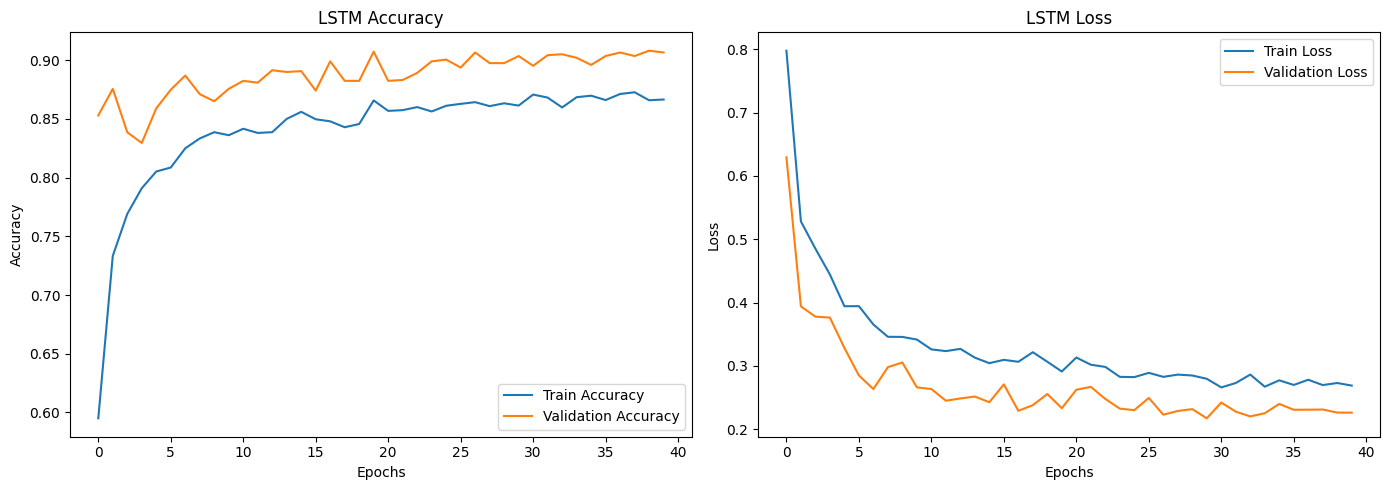

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("LSTM Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("LSTM Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()

plt.savefig(RESULTS_DIR / "lstm_training_curves.png", dpi=300)

plt.show()

Cell 12 — Predictions

In [15]:
y_pred_proba = lstm_model.predict(X_test_lstm)
y_pred = np.argmax(y_pred_proba, axis=1)
y_pred[:10]

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


array([0, 1, 1, 2, 2, 2, 1, 1, 2, 1])

Cell 13 — Metrics

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

lstm_metrics = {
    "Model": "LSTM",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "RMSE": rmse
}

lstm_metrics

{'Model': 'LSTM',
 'Accuracy': 0.8778280542986425,
 'Precision': 0.9024720889963636,
 'Recall': 0.8778280542986425,
 'F1-score': 0.8852324699145919,
 'RMSE': np.float64(0.3495310368212778)}

Cell 14 — Classification report

In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low Risk", "Medium Risk", "High Risk"]
))

              precision    recall  f1-score   support

    Low Risk       0.45      0.88      0.60        74
 Medium Risk       0.91      0.83      0.87       649
   High Risk       0.94      0.93      0.94       603

    accuracy                           0.88      1326
   macro avg       0.77      0.88      0.80      1326
weighted avg       0.90      0.88      0.89      1326



Cell 15 — Confusion matrix

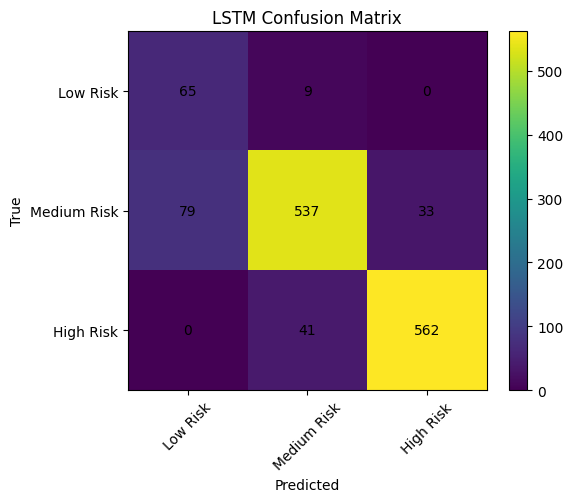

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("LSTM Confusion Matrix")
plt.colorbar()

classes = ["Low Risk", "Medium Risk", "High Risk"]
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "lstm_confusion_matrix.png", dpi=300)
plt.show()

Cell 16 — Save metrics

In [19]:
lstm_metrics_df = pd.DataFrame([lstm_metrics])
lstm_metrics_df.to_csv(RESULTS_DIR / "lstm_metrics.csv", index=False)

lstm_metrics_df

,Model,Accuracy,Precision,Recall,F1-score,RMSE
0,LSTM,0.877828,0.902472,0.877828,0.885232,0.349531


Cell 17 — Save final model

In [20]:
lstm_model.save(MODELS_DIR / "lstm_model_final.h5")

print("LSTM model saved successfully.")

LSTM model saved successfully.
